# JRT results: main-paper tables and figures

Display notebook for the manuscript's main text. It fits nothing: it shows the CSV
and figure outputs of the R pipeline in `../R/` (`01_grm.R`, `02_comparison.R`,
`03_simulations.R`; see `../README.md`) as labelled tables and figures. A few figures
are drawn here from the CSVs. The supplementary objects are in `03_jrt_supplement.ipynb`.
Re-execute both notebooks (seconds) after every pipeline run. Objects whose source file
does not exist yet show a placeholder line.

Numbers in the manuscript text come from these tables through the results-interpreter.

The rated products are the football actions; raters are the judges of judge response
theory. Raters with fewer than 15 ratings are excluded from the whole pipeline (decision
2026-10-22; see `results/data/excluded_raters.csv`). Short notes above each object say
what it shows; references are listed at the end.

In [1]:
from jrt_display import *

## 1. Data basis

**Design.** Size and coverage of the products × raters matrix that every model uses. The design is incomplete: each product is rated by a few raters only, and missing ratings are left out of the likelihood, not imputed. A connected design (one component) is required so that all raters and products lie on one scale (Eckes, 2015).

In [2]:
#| label: tbl-design-summary
#| tbl-cap: "Data basis shared by all models: ratings, products, raters, coverage of the product x rater matrix and connectivity of the design."
show_table("design_summary.csv")

| Quantity                                  | Value               |
|:------------------------------------------|:--------------------|
| n ratings                                 | 9,831               |
| n products                                | 3,841               |
| n raters                                  | 25                  |
| min ratings per rater (exclusion cut-off) | 15                  |
| raters excluded                           | R20;R21;R22;R28;R29 |
| ratings excluded                          | 32                  |
| products dropped                          | 1                   |
| n categories                              | 7                   |
| scale                                     | 1-7                 |
| internal coding                           | rating - 1 (0-6)    |
| ratings per product mean                  | 2.559               |
| ratings per product median                | 2                   |
| ratings per product min                   | 1                   |
| ratings per product max                   | 14                  |
| ratings per product harmonic mean         | 1.819               |
| products with 1 rating                    | 857                 |
| ratings per rater min                     | 47                  |
| ratings per rater max                     | 1,174               |
| matrix fill                               | 0.102               |
| n components                              | 1                   |
| rater pairs total                         | 300                 |
| rater pairs without overlap               | 23                  |
| rater pairs overlap median                | 22.500              |
| raters with category gaps                 | 8                   |
| raters with internal gap                  | 1                   |
| duplicate pairs resolved in 00            | 26                  |
| duplicate pairs conflicting               | 1                   |

**Category use.** Share of each rater's ratings in each of the 7 categories. Raters sorted by mean rating; the labels at the right give the number of ratings and the categories a rater never used. Raters who never use a category get fewer thresholds in mirt, because mirt only models the categories a rater actually used (counts in the supplement).

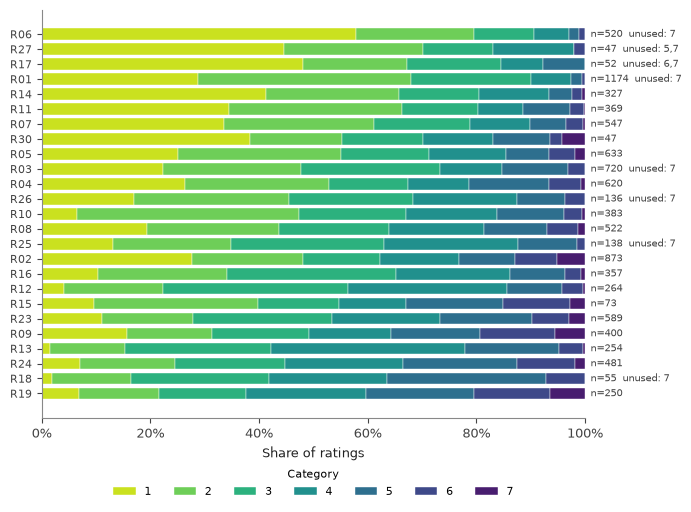

In [3]:
#| label: fig-category-usage-shares
#| fig-cap: "Share of each rater's ratings in each of the 7 categories, sorted by the rater's mean rating. Labels at the right: n = number of ratings, followed by the categories the rater never used."
_cu = read_res("category_usage.csv").merge(read_res("design_summary_raters.csv")[["rater_id", "mean"]], on="rater_id").sort_values("mean", ascending=False)
_cc = [f"cat_{i}" for i in range(1, 8)]
_sh = _cu[_cc].div(_cu[_cc].sum(axis=1), axis=0).to_numpy()
_cm = plt.get_cmap("viridis_r")
with plt.rc_context(PLOT_STYLE):
    _f, _ax = plt.subplots(figsize=(7, 5.2))
    _y = np.arange(len(_cu))
    _left = np.zeros(len(_cu))
    for _j in range(7):
        _ax.barh(_y, _sh[:, _j], left=_left, color=_cm(.08 + .84 * _j / 6), height=.78, label=str(_j + 1), edgecolor="white", lw=.3)
        _left += _sh[:, _j]
    for _i, (_, _r) in enumerate(_cu.iterrows()):
        _un = ",".join(str(_j + 1) for _j in range(7) if _r[_cc[_j]] == 0)
        _ax.text(1.01, _i, f"n={int(_r['n_ratings'])}" + (f"  unused: {_un}" if _un else ""), va="center", fontsize=7.5, color="#444444")
    _ax.set_yticks(_y, _cu["rater_id"], fontsize=8)
    _ax.set_xlim(0, 1)
    _ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    _ax.set_xlabel("Share of ratings")
    _ax.grid(False)
    _ax.legend(title="Category", ncol=7, loc="upper center", bbox_to_anchor=(.5, -.1), fontsize=8, title_fontsize=8)
    _f.tight_layout()
    plt.show()

## 2. Scoring model

**Model comparison.** Judge response theory treats raters as items and products as persons (Myszkowski & Storme, 2019). The retained scoring model is a graded response model (GRM; Samejima, 1969) fitted by marginal maximum likelihood in `mirt` (Chalmers, 2012). The adjacent-category models form a ladder:
- M1, the rating scale model with a rater shift (Andrich, 1978). This is the many-facet Rasch model (Linacre, 1989; Primi et al., 2019), fitted with `sirt::rm.facets`.
- M2, the partial credit model (Masters, 1982): adds rater-specific thresholds.
- M3, the generalized partial credit model (Muraki, 1992): adds rater-specific discriminations.

The GRM belongs to the cumulative family, so it is compared with the ladder by information criteria only (lower is better). Likelihood-ratio tests within the ladder are in the supplement.

In [4]:
#| label: tbl-model-fit
#| tbl-cap: "Fit of the adjacent-category ladder (M1 rating-scale MFRM, M2 partial-credit MFRM, M3 generalized partial credit model) and the graded response model: log-likelihood, number of parameters, information criteria and their difference (delta) to the best model on each criterion."
show_table("model_fit.csv", lambda d: d[["model", "software", "family", "logLik", "npar", "AIC", "BIC", "SABIC", "delta_AIC", "delta_BIC", "delta_SABIC"]])

| Model                    | Software        | Family                        | Log-likelihood   | Parameters   | AIC        | BIC        | SABIC      | ΔAIC    | ΔBIC   | ΔSABIC   |
|:-------------------------|:----------------|:------------------------------|:-----------------|:-------------|:-----------|:-----------|:-----------|:--------|:-------|:---------|
| M1 (rating-scale MFRM)   | sirt::rm.facets | adjacent category             | -15,180.581      | 31           | 30,423.163 | 30,617.021 | 30,518.517 | 837.551 | 0.000  | 425.373  |
| M2 (partial-credit MFRM) | mirt            | adjacent category             | -14,741.291      | 141          | 29,764.582 | 30,646.324 | 30,198.292 | 178.970 | 29.303 | 105.147  |
| M3 (GPCM)                | mirt            | adjacent category             | -14,652.571      | 165          | 29,635.141 | 30,666.967 | 30,142.674 | 49.530  | 49.946 | 49.530   |
| GRM                      | mirt            | cumulative (not in LR ladder) | -14,627.806      | 165          | 29,585.612 | 30,617.437 | 30,093.144 | 0.000   | 0.416  | 0.000    |

## 3. Reliability and number of ratings

**Reliability by number of ratings.** Product scores are EAP estimates with the posterior SD (PSD) as their standard error; rel_post = 1 − PSD² gives each product's reliability from its own raters, rel_info the same from the information of the product's raters at the EAP estimate. The table shows how product-level precision grows with the number of ratings a product received. The overall indices (empirical marginal reliability, model-based reliability of the full panel, naive indices) are in the supplement.

In [5]:
#| label: tbl-grm-reliability-by-n
#| tbl-cap: "Product-level reliability and posterior SD by number of ratings per product."
show_table("reliability_by_n_ratings.csv", lambda d: d.rename(columns={"n_ratings": "ratings_per_product"}))

| Ratings per product   | Products   | Mean rel_post   | Median rel_post   | Mean rel_info   | Mean PSD   |
|:----------------------|:-----------|:----------------|:------------------|:----------------|:-----------|
| 1                     | 857        | 0.526           | 0.541             | 0.546           | 0.683      |
| 2                     | 2,227      | 0.703           | 0.713             | 0.717           | 0.540      |
| 3                     | 73         | 0.770           | 0.777             | 0.791           | 0.472      |
| 4                     | 93         | 0.815           | 0.834             | 0.817           | 0.425      |
| 5                     | 143        | 0.852           | 0.860             | 0.858           | 0.382      |
| 6                     | 185        | 0.879           | 0.886             | 0.882           | 0.346      |
| 7                     | 124        | 0.891           | 0.897             | 0.897           | 0.328      |
| 8                     | 77         | 0.904           | 0.908             | 0.907           | 0.308      |
| 9                     | 25         | 0.917           | 0.923             | 0.916           | 0.286      |
| 10                    | 22         | 0.915           | 0.926             | 0.917           | 0.286      |
| 11                    | 8          | 0.919           | 0.925             | 0.921           | 0.282      |
| 12                    | 5          | 0.931           | 0.928             | 0.930           | 0.261      |
| 13                    | 1          | 0.944           | 0.944             | 0.945           | 0.237      |
| 14                    | 1          | 0.955           | 0.955             | 0.954           | 0.211      |

**Observed and simulated reliability by number of ratings.** Dots: mean rel_post of the actual products with that many ratings. Line and band: the projection from the fitted GRM, in which simulated products with θ ~ N(0, 1) each receive k ratings from k raters of the panel drawn at random (equal probability), with ratings generated and scored by the fitted GRM (parameters treated as known; 50 replications of 2,000 products per k). Dashed lines: the actual design topped up so that every product has at least 4 ratings (simulated the same way), and the model-based reliability of the hypothetical full panel. Tables with the values are in the supplement.

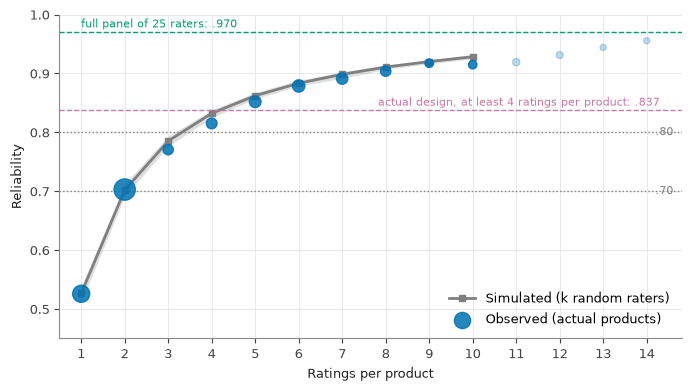

In [6]:
#| label: fig-grm-reliability-observed-vs-simulated
#| fig-cap: "Reliability by number of ratings per product. Dots: observed mean product-level reliability (1 − PSD²) of the actual products with that many ratings (dot size = number of products; faded = fewer than 10 products). Line and band: simulated empirical marginal reliability (mean and 95% range over 50 replications) for products that each receive exactly k ratings from k raters drawn at random from the panel with equal probability, with ratings generated and scored by the fitted GRM. Dashed lines: simulated reliability of the actual design topped up to at least 4 ratings per product, and model-based reliability of the hypothetical full panel."
_pr = read_res("reliability_projection.csv")
_bn = read_res("reliability_by_n_ratings.csv")
_m4 = read_res("reliability_min_ratings.csv").set_index("design").loc["min_4"]
_full = float(read_res("reliability_overview.csv").set_index("index")["value"]["GRM: model-based marginal reliability"])
_nr = int(float(read_res("design_summary.csv").set_index("quantity")["value"]["n_raters"]))
with plt.rc_context(PLOT_STYLE):
    _f, _ax = plt.subplots(figsize=(7, 4))
    _ax.fill_between(_pr["k"], _pr["empirical_q025"], _pr["empirical_q975"], color=C["grey"], alpha=.25, lw=0)
    _ax.plot(_pr["k"], _pr["empirical"], color=C["grey"], lw=2, marker="s", ms=4, label="Simulated (k random raters)")
    _big = _bn["n_products"] >= 10
    _sz = 15 + 220 * np.sqrt(_bn["n_products"] / _bn["n_products"].max())
    _ax.scatter(_bn.loc[_big, "n_ratings"], _bn.loc[_big, "rel_post_mean"], s=_sz[_big], color=C["blue"], alpha=.85, zorder=3, label="Observed (actual products)")
    _ax.scatter(_bn.loc[~_big, "n_ratings"], _bn.loc[~_big, "rel_post_mean"], s=_sz[~_big], color=C["blue"], alpha=.25, zorder=3)
    _xmax = int(_bn["n_ratings"].max())
    for _lvl in (.70, .80):
        _ax.axhline(_lvl, color=C["grey"], ls=":", lw=1)
        _ax.text(_xmax + .2, _lvl, f"{_lvl:.2f}".lstrip("0"), va="center", fontsize=8, color=C["grey"])
    _ax.axhline(_m4["empirical"], color=C["purple"], ls="--", lw=1)
    _ax.text(_xmax + .3, _m4["empirical"] + .008, f"actual design, at least 4 ratings per product: {r3(_m4['empirical'])}", fontsize=8, color=C["purple"], ha="right")
    _ax.axhline(_full, color=C["green"], ls="--", lw=1)
    _ax.text(1, _full + .008, f"full panel of {_nr} raters: {r3(_full)}", fontsize=8, color=C["green"])
    _ax.set_xticks(range(1, _xmax + 1))
    _ax.set_xlim(.5, _xmax + .8)
    _ax.set_ylim(.45, 1.0)
    _ax.set_xlabel("Ratings per product")
    _ax.set_ylabel("Reliability")
    _ax.legend(loc="lower right")
    _f.tight_layout()
    plt.show()

In [7]:
_pr = read_res("reliability_projection.csv")
print(f"{int(_pr['n_reps'].iloc[0])} replications of {int(_pr['n_products_per_rep'].iloc[0])} simulated products per k; seed {int(_pr['seed'].iloc[0])}.")
_k80 = _pr.loc[_pr["empirical"] >= 0.80, "k"]
print("Smallest k with simulated empirical reliability of at least .80: " + (str(int(_k80.min())) if len(_k80) else "none up to k = " + str(int(_pr["k"].max()))) + ".")

50 replications of 2000 simulated products per k; seed 20260713.
Smallest k with simulated empirical reliability of at least .80: 4.


## 4. Raters

**Rater severity under M1.** The rating-scale MFRM summarises each rater in one severity parameter (0 = average rater; higher = stricter), shown with 95% intervals next to the rater's raw mean rating.

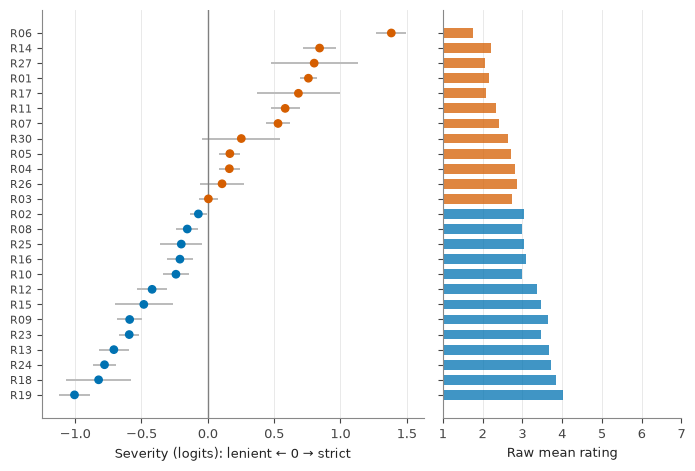

In [8]:
#| label: fig-m1-rater-severity
#| fig-cap: "Left: rater severity in M1 (rating-scale MFRM) with 95% intervals (estimate ± 1.96 SE); 0 = average rater, higher = stricter. Right: the rater's raw mean rating (1–7). Raters sorted by severity."
_sv = read_res("rater_parameters_by_model.csv")
_sv = _sv[(_sv["model"] == "M1_RSM") & (_sv["parameter"] == "b_rater")][["rater_id", "estimate", "se"]].merge(
    read_res("design_summary_raters.csv")[["rater_id", "n_ratings", "mean"]], on="rater_id").sort_values("estimate")
with plt.rc_context(PLOT_STYLE):
    _f, (_a1, _a2) = plt.subplots(1, 2, figsize=(7, 4.8), sharey=True, gridspec_kw=dict(width_ratios=[1.6, 1]))
    _y = np.arange(len(_sv))
    _col = np.where(_sv["estimate"] > 0, C["red"], C["blue"])
    _a1.errorbar(_sv["estimate"], _y, xerr=1.96 * _sv["se"], fmt="none", ecolor="#BBBBBB", elinewidth=1.4)
    _a1.scatter(_sv["estimate"], _y, c=_col, s=28, zorder=3)
    _a1.axvline(0, color=C["grey"], lw=1)
    _a1.set_yticks(_y, _sv["rater_id"], fontsize=8)
    _a1.set_xlabel("Severity (logits): lenient ← 0 → strict")
    _a1.grid(axis="y", visible=False)
    _a2.barh(_y, _sv["mean"], color=_col, alpha=.75, height=.65)
    _a2.set_xlim(1, 7)
    _a2.set_xlabel("Raw mean rating")
    _a2.grid(axis="y", visible=False)
    _f.tight_layout()
    plt.show()

In [9]:
_sv = read_res("rater_parameters_by_model.csv")
_sv = _sv[(_sv["model"] == "M1_RSM") & (_sv["parameter"] == "b_rater")].sort_values("estimate")
_lo, _hi = _sv.iloc[0], _sv.iloc[-1]
print(f"M1 severity ranges from {_lo['estimate']:.3f} (SE {_lo['se']:.3f}, {_lo['rater_id']}) to {_hi['estimate']:.3f} (SE {_hi['se']:.3f}, {_hi['rater_id']}): a span of {_hi['estimate'] - _lo['estimate']:.3f} logits.")

M1 severity ranges from -1.005 (SE 0.059, R19) to 1.383 (SE 0.058, R06): a span of 2.388 logits.


**Rater parameters (GRM).** a is the rater's discrimination: how sharply the ratings separate products of different creativity. b_k is the θ at which a rating above category k becomes more likely than a rating of k or below; higher b means a stricter rater. For a rater without an internal category gap, b_k separates categories k and k + 1; raters who never used the top categories have no estimate for the highest thresholds. For a rater with an internal gap (an unused category inside the observed range), the thresholds separate other category boundaries and are not directly comparable with those of the other raters.

In [10]:
#| label: tbl-grm-rater-parameters
#| tbl-cap: "Rater parameters of the graded response model in IRT metric: discrimination a and thresholds b1 to b6 (bk separates rating categories k and k + 1), each as estimate (standard error). A dash marks a threshold above the highest category a rater used."
show_table("rater_parameters.csv", lambda d: est_se(d, ["a"] + [f"b{k}" for k in range(1, 7) if f"b{k}" in d])[["rater_id", "n_ratings", "a"] + [f"b{k}" for k in range(1, 7) if f"b{k}" in d]])

| Rater   | Ratings by rater   | a           | b1           | b2           | b3           | b4          | b5          | b6          |
|:--------|:-------------------|:------------|:-------------|:-------------|:-------------|:------------|:------------|:------------|
| R01     | 1,174              | 1.79 (0.13) | -0.83 (0.06) | 0.59 (0.05)  | 1.79 (0.10)  | 2.86 (0.16) | 3.94 (0.29) | –           |
| R02     | 873                | 2.60 (0.30) | -0.68 (0.06) | -0.02 (0.05) | 0.40 (0.05)  | 0.90 (0.06) | 1.40 (0.08) | 2.02 (0.12) |
| R03     | 720                | 1.85 (0.17) | -1.11 (0.08) | -0.16 (0.06) | 0.76 (0.07)  | 1.29 (0.10) | 2.49 (0.19) | –           |
| R04     | 620                | 2.05 (0.22) | -0.76 (0.08) | 0.17 (0.06)  | 0.67 (0.07)  | 1.11 (0.08) | 2.06 (0.14) | 3.43 (0.30) |
| R05     | 633                | 2.36 (0.22) | -0.84 (0.07) | 0.12 (0.05)  | 0.66 (0.06)  | 1.27 (0.08) | 1.85 (0.12) | 2.68 (0.19) |
| R06     | 520                | 3.15 (0.45) | 0.24 (0.05)  | 0.97 (0.07)  | 1.52 (0.10)  | 2.17 (0.15) | 2.59 (0.21) | –           |
| R07     | 547                | 1.91 (0.16) | -0.52 (0.07) | 0.45 (0.07)  | 1.14 (0.09)  | 1.80 (0.12) | 2.58 (0.18) | 3.99 (0.44) |
| R08     | 522                | 2.11 (0.24) | -1.19 (0.10) | -0.30 (0.06) | 0.39 (0.07)  | 1.11 (0.09) | 1.91 (0.14) | 3.03 (0.26) |
| R09     | 400                | 0.95 (0.15) | -1.99 (0.30) | -0.96 (0.18) | -0.04 (0.12) | 0.72 (0.15) | 1.78 (0.25) | 3.44 (0.48) |
| R10     | 383                | 2.37 (0.32) | -2.01 (0.16) | -0.20 (0.07) | 0.44 (0.08)  | 1.08 (0.11) | 2.03 (0.19) | 3.21 (0.40) |
| R11     | 369                | 1.95 (0.20) | -0.47 (0.08) | 0.61 (0.08)  | 1.18 (0.10)  | 1.67 (0.13) | 2.69 (0.24) | 4.04 (0.59) |
| R12     | 264                | 2.91 (0.50) | -2.01 (0.20) | -0.88 (0.10) | 0.20 (0.08)  | 1.32 (0.12) | 2.19 (0.19) | 3.50 (0.46) |
| R13     | 254                | 1.49 (0.21) | -3.43 (0.49) | -1.56 (0.19) | -0.32 (0.11) | 1.14 (0.16) | 2.59 (0.32) | 4.39 (0.82) |
| R14     | 327                | 2.45 (0.45) | -0.17 (0.08) | 0.56 (0.08)  | 1.09 (0.11)  | 1.91 (0.18) | 2.56 (0.26) | 3.35 (0.42) |
| R15     | 73                 | 2.71 (0.52) | -1.67 (0.24) | -0.23 (0.14) | 0.26 (0.13)  | 0.64 (0.14) | 1.31 (0.19) | 2.66 (0.42) |
| R16     | 357                | 2.37 (0.21) | -1.56 (0.12) | -0.53 (0.07) | 0.46 (0.07)  | 1.38 (0.10) | 2.41 (0.18) | 3.28 (0.31) |
| R17     | 52                 | 1.73 (0.51) | -0.19 (0.20) | 0.45 (0.23)  | 1.15 (0.35)  | 1.73 (0.50) | –           | –           |
| R18     | 55                 | 0.65 (0.26) | -6.39 (2.92) | -2.66 (1.15) | -0.53 (0.48) | 0.96 (0.57) | 4.34 (1.72) | –           |
| R19     | 250                | 1.97 (0.39) | -1.97 (0.25) | -1.02 (0.15) | -0.40 (0.11) | 0.33 (0.10) | 1.10 (0.15) | 2.10 (0.26) |
| R23     | 589                | 1.71 (0.13) | -1.77 (0.12) | -0.93 (0.08) | 0.01 (0.06)  | 0.81 (0.08) | 1.85 (0.13) | 2.87 (0.20) |
| R24     | 481                | 2.56 (0.20) | -1.78 (0.11) | -0.83 (0.07) | -0.17 (0.06) | 0.51 (0.06) | 1.41 (0.09) | 2.72 (0.19) |
| R25     | 138                | 3.03 (0.45) | -1.28 (0.14) | -0.46 (0.10) | 0.35 (0.09)  | 1.28 (0.14) | 2.42 (0.34) | –           |
| R26     | 136                | 4.17 (1.49) | -0.98 (0.14) | -0.12 (0.09) | 0.53 (0.11)  | 1.32 (0.16) | 2.12 (0.25) | –           |
| R27     | 47                 | 2.85 (0.82) | -0.24 (0.16) | 0.48 (0.17)  | 0.95 (0.22)  | 2.23 (0.51) | –           | –           |
| R30     | 47                 | 2.69 (0.69) | -0.27 (0.17) | 0.21 (0.16)  | 0.63 (0.18)  | 1.16 (0.25) | 2.11 (0.39) | 2.56 (0.48) |

Discrimination per rater as a figure, with 95% intervals (estimate ± 1.96 SE). Under M1 and M2 all raters would share one value.

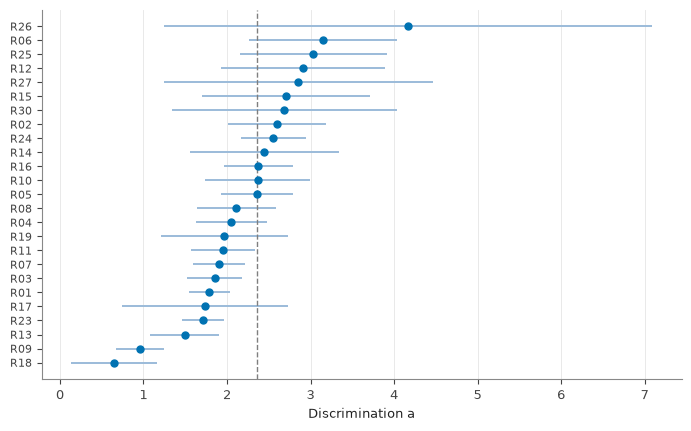

In [11]:
#| label: fig-grm-rater-discrimination-ci
#| fig-cap: "Discrimination a per rater in the graded response model with 95% intervals (estimate ± 1.96 SE), sorted by a. Dashed line: median. Under the Rasch-family models M1 and M2 all raters share one value."
_g = read_res("rater_parameters.csv").sort_values("a")
with plt.rc_context(PLOT_STYLE):
    _f, _ax = plt.subplots(figsize=(7, 4.4))
    _y = np.arange(len(_g))
    _ax.errorbar(_g["a"], _y, xerr=1.96 * _g["a_se"], fmt="o", color=C["blue"], ecolor="#9BBBD9", elinewidth=1.4, capsize=0, ms=5)
    _ax.axvline(_g["a"].median(), ls="--", color=C["grey"], lw=1)
    _ax.set_yticks(_y, _g["rater_id"], fontsize=8)
    _ax.set_xlabel("Discrimination a")
    _ax.grid(axis="y", visible=False)
    _f.tight_layout()
    plt.show()

**Category response functions.** The probability of each rating category as a function of θ, one panel per rater.

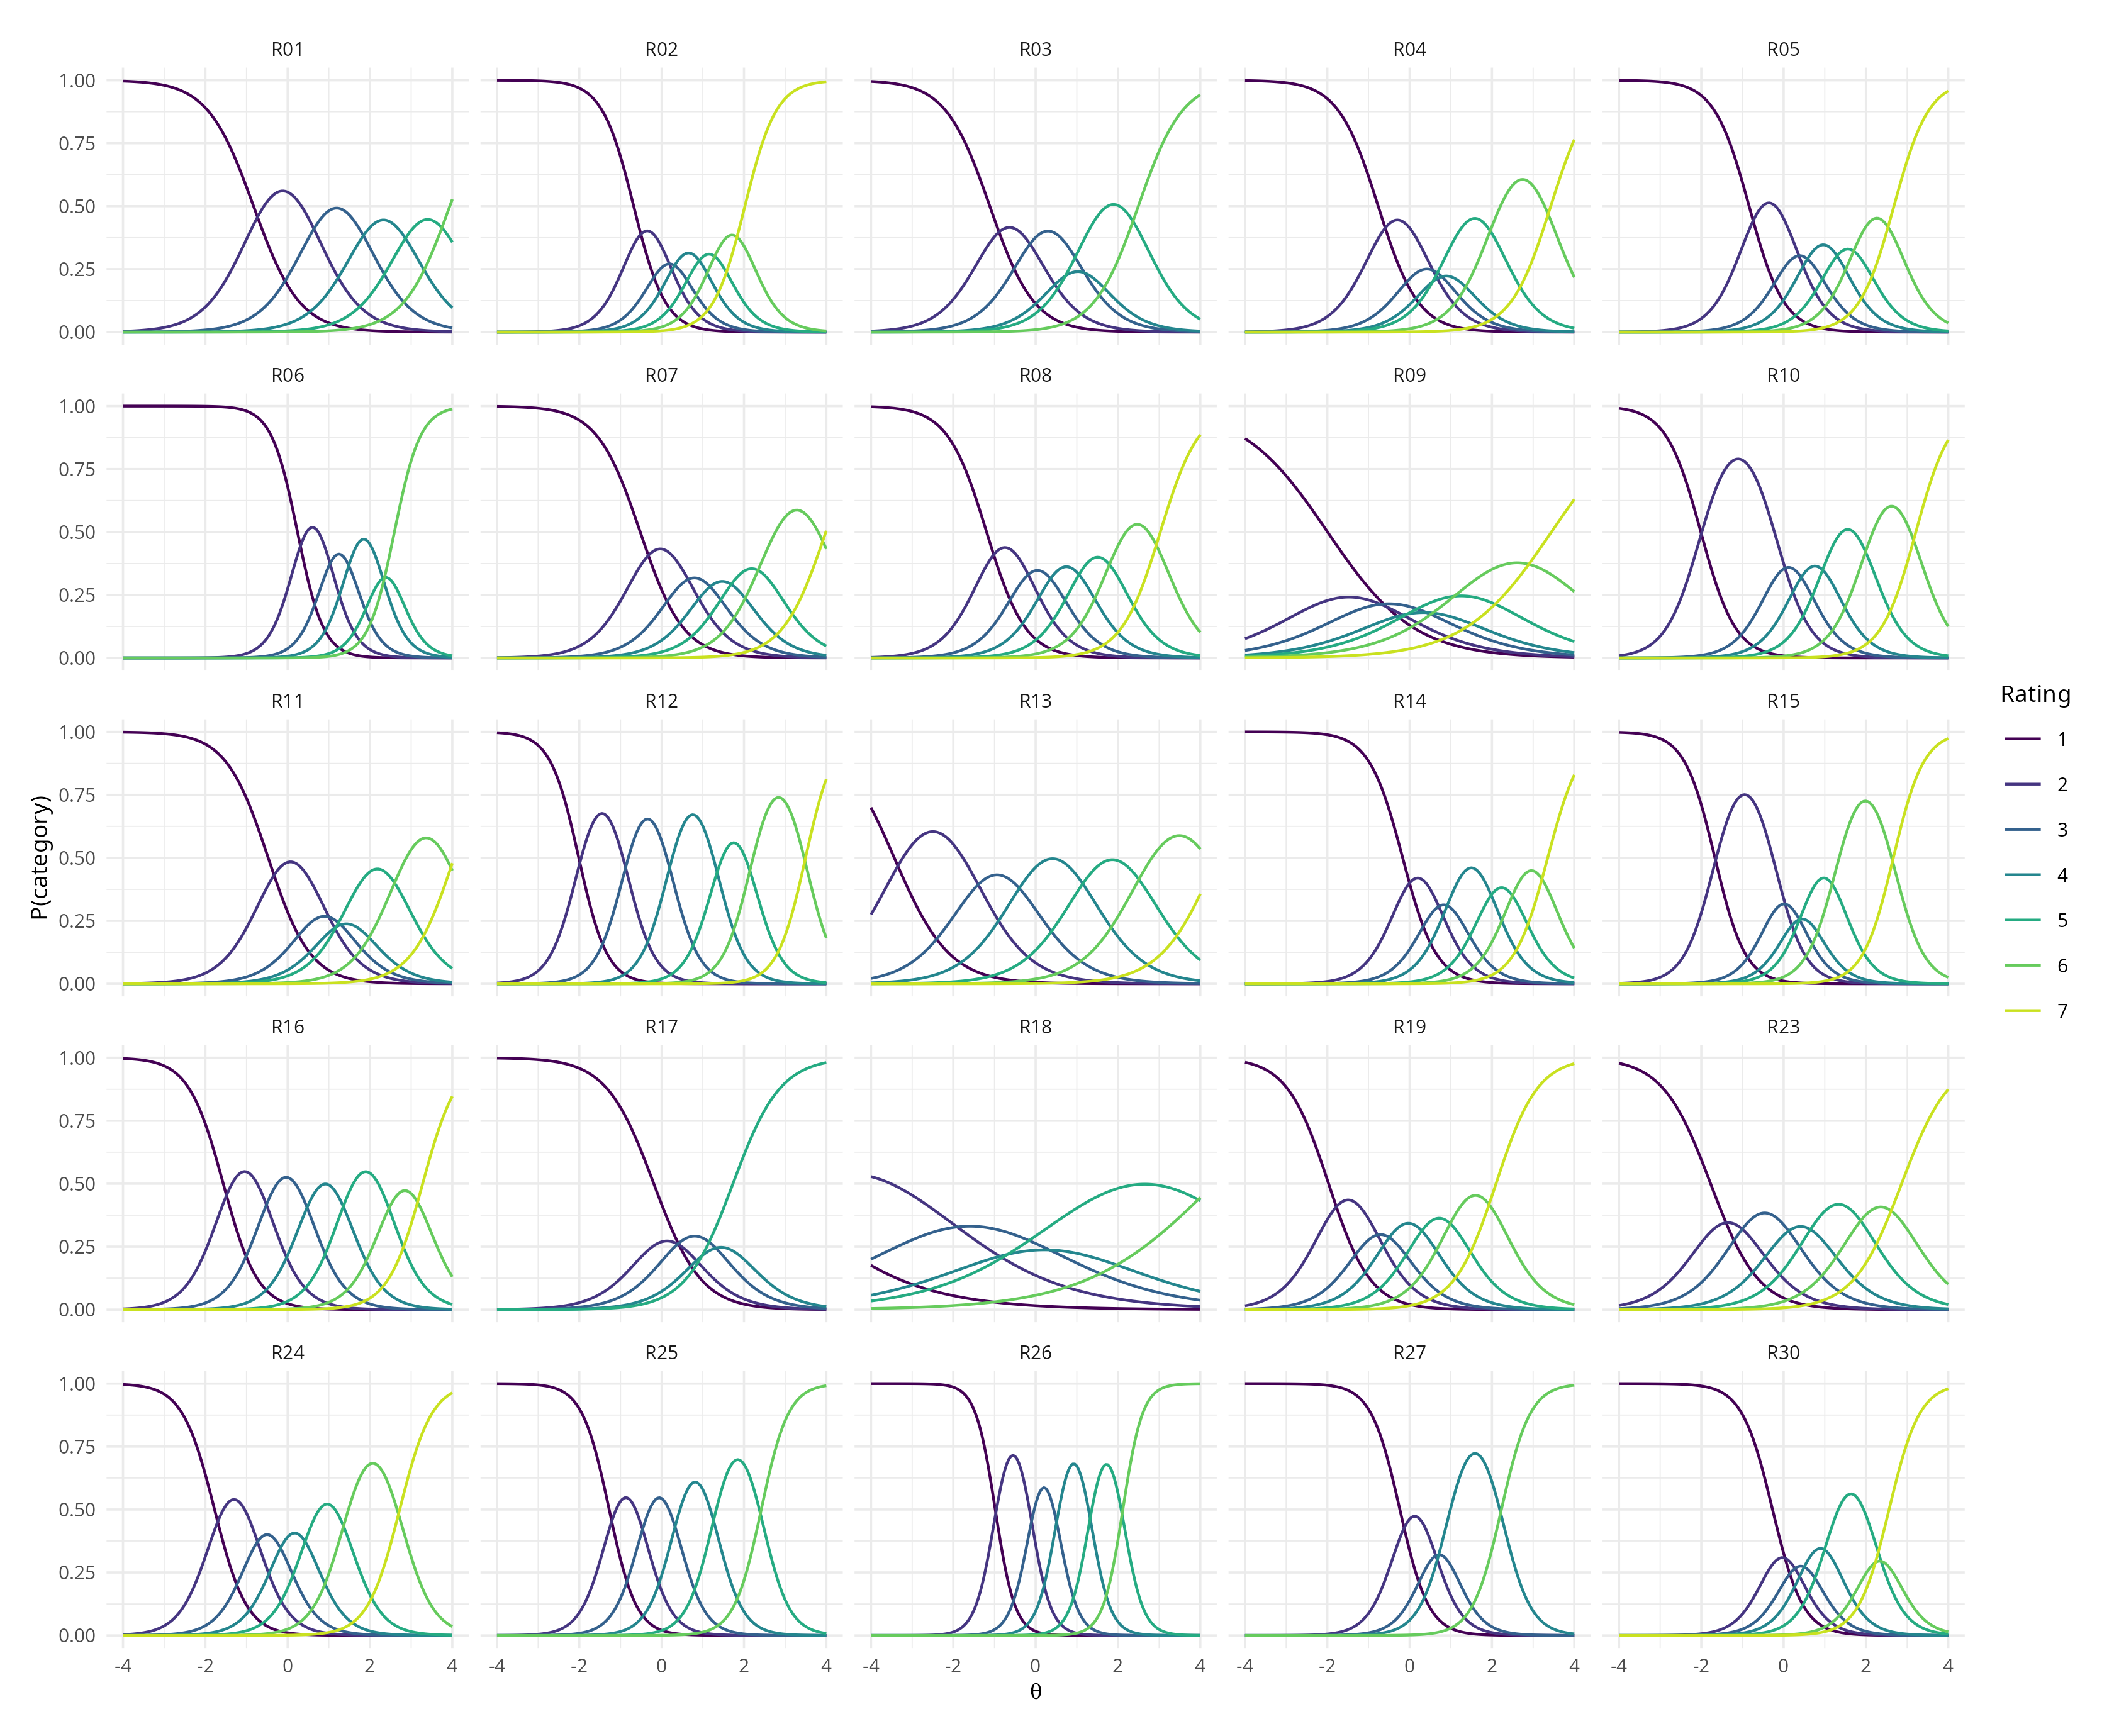

In [12]:
#| label: fig-grm-category-response-functions
#| fig-cap: "Category response functions of the graded response model for each rater."
show_png("grm_category_response_functions.png", width=11)

**Rater information.** I_j(θ) shows how much a rater's rating tells about θ at each level of creativity. Information from different raters adds up under local independence. The first figure gives each rater's average information per rating (information integrated over θ ~ N(0, 1)) with 95% intervals from 200 accepted draws of the model parameters from their asymptotic normal distribution; wide intervals mean that a rater's informativeness is not yet well determined, typically for raters with few ratings. The second figure shows the full information functions.

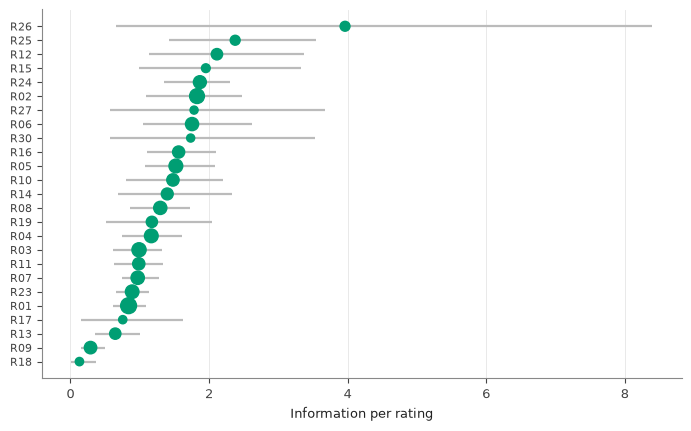

In [13]:
#| label: fig-grm-rater-information-ci
#| fig-cap: "Average information per rating (information integrated over θ ~ N(0, 1)) for each rater with 95% intervals from 200 accepted parameter draws, sorted by information. Point size is proportional to the square root of the rater's number of ratings."
_i = read_res("rater_information_ci.csv").sort_values("info_weighted_area")
with plt.rc_context(PLOT_STYLE):
    _f, _ax = plt.subplots(figsize=(7, 4.4))
    _y = np.arange(len(_i))
    _ax.hlines(_y, _i["info_ci_low"], _i["info_ci_high"], color="#BBBBBB", lw=1.6)
    _ax.scatter(_i["info_weighted_area"], _y, s=10 + 120 * np.sqrt(_i["n_ratings"] / _i["n_ratings"].max()), color=C["green"], zorder=3)
    _ax.set_yticks(_y, _i["rater_id"], fontsize=8)
    _ax.set_xlabel("Information per rating")
    _ax.grid(axis="y", visible=False)
    _f.tight_layout()
    plt.show()

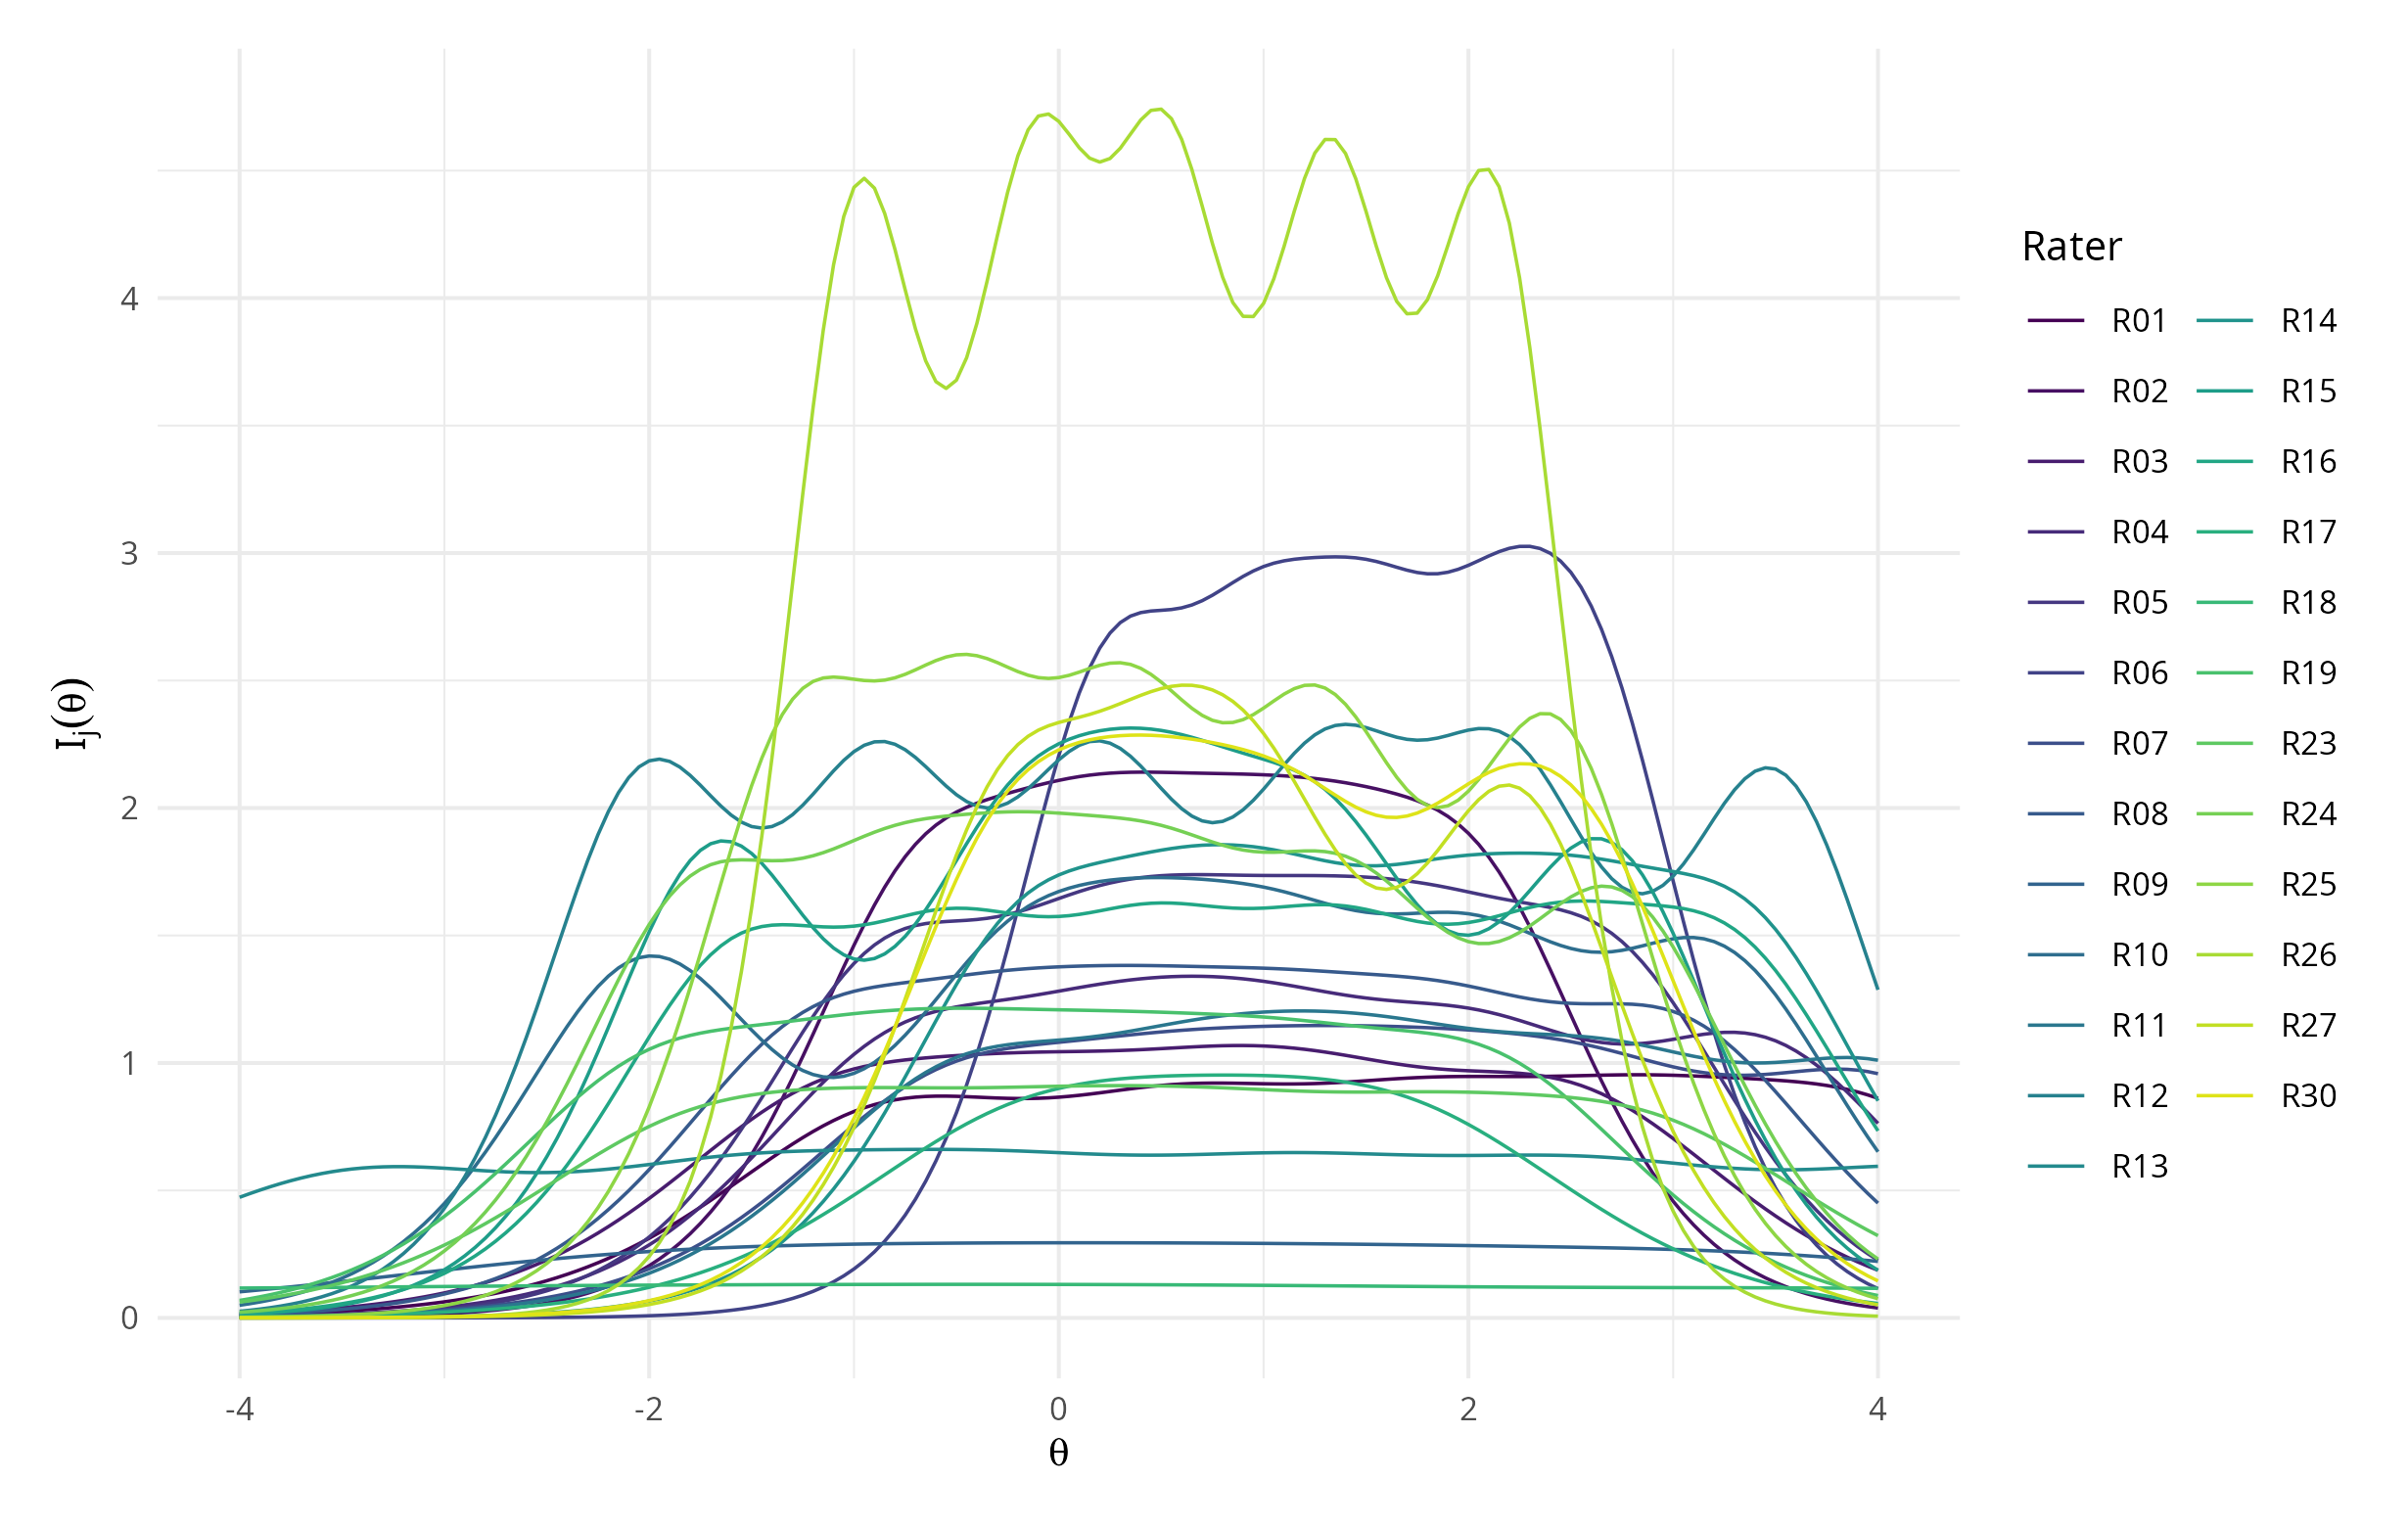

In [14]:
#| label: fig-grm-rater-information
#| fig-cap: "Rater information functions of the graded response model."
show_png("grm_rater_information.png")

## 5. Scores: raw mean versus GRM, agreement between models

**Raw mean versus GRM score.** Common practice scores a product by the unweighted mean of its ratings, which treats all raters as interchangeable. The table compares this raw mean with the GRM score, separately for products with 1, 2 and 3 or more ratings. The raw mean is tied for almost all products (with one rating it takes only 7 values), so agreement is given as Kendall's τ-b and as the share of product pairs with different raw means that the GRM orders the other way round. The last two columns show how far apart the GRM scores of products with the same raw mean lie: products with the same raw mean get different GRM scores when they were rated by raters of different severity or discrimination.

In [15]:
#| label: tbl-raw-mean-vs-grm
#| tbl-cap: "Raw mean rating versus GRM score by number of ratings per product: Kendall's tau-b, share of product pairs in reversed order, and range of GRM scores among products with the same raw mean."
show_table("raw_mean_vs_grm.csv", lambda d: d.rename(columns={"n_ratings": "ratings_per_product"}))

| Ratings per product   | Products   | Kendall's τ-b   | Share of pairs in reversed order   | Mean θ̂ range at equal raw mean   | Maximum θ̂ range at equal raw mean   |
|:----------------------|:-----------|:----------------|:-----------------------------------|:---------------------------------|:------------------------------------|
| 1                     | 857        | 0.773           | 0.076                              | 1.240                            | 1.420                               |
| 2                     | 2,227      | 0.818           | 0.066                              | 1.558                            | 2.129                               |
| 3+                    | 757        | 0.861           | 0.065                              | 0.507                            | 1.306                               |

The same comparison as a figure. Each point is a product; the vertical spread at a given raw mean shows the products whose GRM scores differ although their raw means are equal.

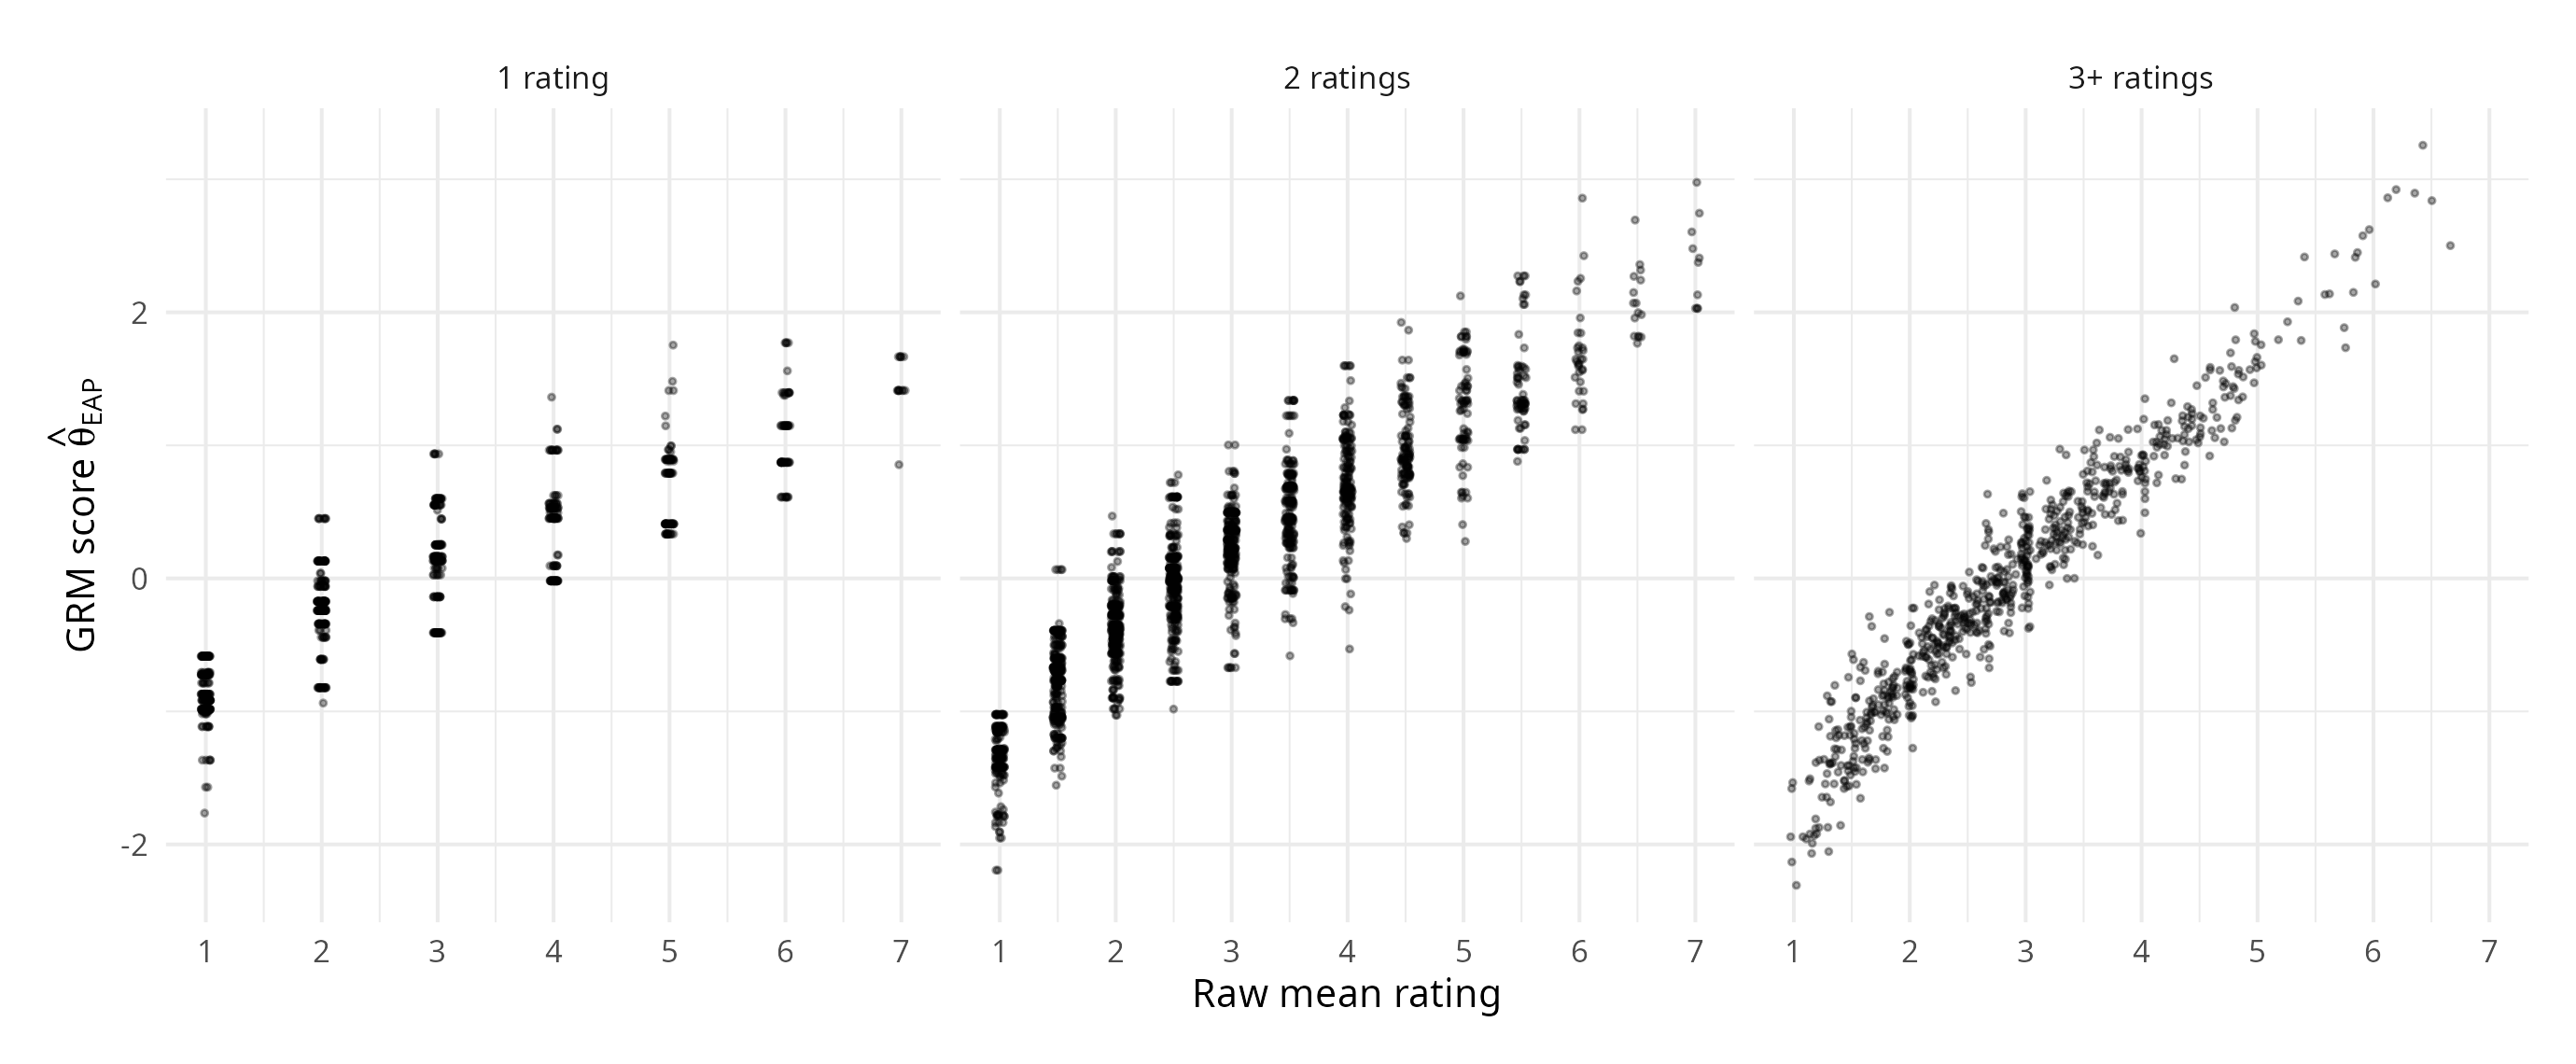

In [16]:
#| label: fig-raw-mean-vs-theta
#| fig-cap: "GRM score (EAP) against the raw mean rating of each product, by number of ratings per product. Points are jittered horizontally."
show_png("grm_raw_mean_vs_theta.png", width=9)

**Change in product ranking.** How far products move in the ranking when another model replaces the GRM: correlations, the mean and 95th-percentile shift in percentile rank, and the share of products that change quintile.

In [17]:
#| label: tbl-score-agreement
#| tbl-cap: "Change of the product ranking relative to the GRM: correlations, absolute shift in percentile rank (0-1 scale) and share of products whose quintile changes."
show_table("score_agreement.csv", lambda d: d.drop(columns=["reference"]))

| Model                    | Pearson r   | Spearman ρ   | Mean percentile shift   | 95th percentile of shift   | Maximum shift   | Share changing quintile   | Share changing ≥ 2 quintiles   |
|:-------------------------|:------------|:-------------|:------------------------|:---------------------------|:----------------|:--------------------------|:-------------------------------|
| M1 (rating-scale MFRM)   | 0.978       | 0.980        | 0.040                   | 0.123                      | 0.432           | 0.188                     | 0.003                          |
| M2 (partial-credit MFRM) | 0.986       | 0.984        | 0.032                   | 0.111                      | 0.404           | 0.155                     | 0.005                          |
| M3 (GPCM)                | 0.996       | 0.997        | 0.016                   | 0.046                      | 0.225           | 0.073                     | 0.000                          |

## References

- Andrich, D. (1978). A rating formulation for ordered response categories. *Psychometrika, 43*(4), 561–573.
- Chalmers, R. P. (2012). mirt: A multidimensional item response theory package for the R environment. *Journal of Statistical Software, 48*(6), 1–29.
- Eckes, T. (2015). *Introduction to many-facet Rasch measurement* (2nd ed.). Peter Lang.
- Linacre, J. M. (1989). *Many-facet Rasch measurement*. MESA Press.
- Masters, G. N. (1982). A Rasch model for partial credit scoring. *Psychometrika, 47*(2), 149–174.
- Muraki, E. (1992). A generalized partial credit model: Application of an EM algorithm. *Applied Psychological Measurement, 16*(2), 159–176.
- Myszkowski, N., & Storme, M. (2019). Judge response theory? A call to upgrade our psychometrical account of creativity judgments. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 167–175.
- Primi, R., Silvia, P. J., Jauk, E., & Benedek, M. (2019). Applying many-facet Rasch modeling in the assessment of creativity. *Psychology of Aesthetics, Creativity, and the Arts, 13*(2), 176–186.
- Samejima, F. (1969). Estimation of latent ability using a response pattern of graded scores. *Psychometrika Monograph Supplement*, No. 17.